In [1]:
import sys
import os
import pickle
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
from rdkit import Chem

# Ensure src is in path to import quartz
sys.path.append(os.path.abspath('src'))

from quartz.data import MoleculeData
from quartz.grids import create_grid, to_dxgrid
from quartz.dataprocessing import calculate_average, calculate_boltz_avg, calculate_pki_avg, pair_overlap

In [2]:
grids = pickle.load(open("grids.pkl", "rb"))

In [2]:
# Load PDBs from directory and map to Excel Data
ligands_dir = Path('~/Documents/Uni/Major/Ligands/cocrys_ligs').expanduser()
charges_dir = Path('tests/sample_data/FXa_PDB_RESP_charges')
excel_path = Path('~/Documents/Uni/Major/Ligands/full_database_ligands.xlsx').expanduser()


In [6]:
# Read Excel file
print(f"Reading Excel file: {excel_path}")
fx_data = pd.read_excel(excel_path)
# Clean column names by stripping whitespace
fx_data.columns = fx_data.columns.str.strip()

pdb_files = list(ligands_dir.glob("*_out_reduced.pdb"))

mol_data_list = []

print(f"Found {len(pdb_files)} PDB files in {ligands_dir}")

for pdb_file in pdb_files:
    # Extract PDB ID from filename (e.g. 1EZQ_out_reduced.pdb -> 1EZQ)
    pdb_id = pdb_file.name.split('_')[0]
    print(f"Processing PDB ID: {pdb_id}")

    extra = defaultdict(float)

    with open(pdb_file, 'r') as f:
        pdb_content = f.readlines()
        for line in pdb_content:
            # print(line)
            if line.startswith("REMARK"):
                print(line.strip())
                if "minimizedAffinity" in line:
                    extra['minimizedAffinity'] = float(line.split()[-1])
                    # print("Minimized Affinity:", extra['minimizedAffinity'])
                if "CNNscore" in line:
                    extra['CNNscore'] = float(line.split()[-1])
                    # print("CNN Score:", extra['CNNscore'])
                if "CNNaffinity" in line:
                    extra['CNNaffinity'] = float(line.split()[-1])
                    # print("CNN Affinity:", extra['CNNaffinity'])

            if extra["minimizedAffinity"] and extra["CNNscore"] and extra["CNNaffinity"]:
                break
    
    # Get pKi and Ki for the PDB ID
    # Assuming column is 'PDB ID' after stripping
    row = fx_data[fx_data['PDB ID'].astype(str).str.strip() == pdb_id]
    
    if row.empty:
        print(f"No FX Data found for {pdb_id}")
        continue
        
    # Handle potential duplicates or just take first
    ki = float(row['Ki (nM)'].values[0])
    # print("Ki:", ki)
    if 'pKi' in row.columns:
        pki = float(row['pKi'].values[0])
    else:
        pki = -np.log10(ki * 1e-9)  # Convert Ki in nM to pKi
    # print("pKi:", pki)

    # Load Mol from PDB
    mol = Chem.MolFromPDBFile(str(pdb_file), removeHs=False)
    if mol is None:
        print(f"Failed to load PDB: {pdb_file.name}")
        continue

    # Path to charge file
    charge_file = charges_dir / f"{pdb_id}_out_reduced.csv"
    
    if not charge_file.exists():
        print(f"Charge file not found for {pdb_id}")
        continue
        
    charges_df = pd.read_csv(charge_file)
    
    # Check atom count and charge assignment
    if len(charges_df) != mol.GetNumAtoms():
        print(f"Atom count mismatch for {pdb_id}: mol {mol.GetNumAtoms()} vs csv {len(charges_df)}")
        continue

    # Assign RESP charges
    charge_sum = 0.0
    for idx, row_charge in charges_df.iterrows():
        atom = mol.GetAtomWithIdx(idx)
        resp_charge = float(row_charge['RESP'])
        atom.SetProp("RESP", str(resp_charge))
        charge_sum += resp_charge
        
        # Verify assignment
        if abs(float(atom.GetProp("RESP")) - resp_charge) > 1e-6:
             print(f"Charge assignment failed for {pdb_id} atom {idx}")

    # print(f"Processed {pdb_id}: Total Charge = {charge_sum:.4f}")
        
    # Create MoleculeData
    md = MoleculeData(
        atomic_numbers=np.array([a.GetAtomicNum() for a in mol.GetAtoms()]),
        coordinates=mol.GetConformer().GetPositions(),
        res={},
        smiles=Chem.MolToSmiles(mol),
        rdmol=mol,
        pdb_code=pdb_id,
        filename=pdb_id,
        ki=ki,
        pki=pki,
        extra=extra
    )
    mol_data_list.append(md)

print(f"Prepared {len(mol_data_list)} MoleculeData objects")

# Generate grids
print("Generating grids...")
grids = create_grid(mol_data_list, props=["RESP"], size=0.5, threshold=0.0001)

# Save to pkl
output_file = 'grids.pkl'
with open(output_file, 'wb') as f:
    pickle.dump(grids, f)
    
# print(f"Saved grids to {output_file}")

# # Save to DX
# print("Saving to DX format...")
# to_dxgrid(grids)
# print("Saved DX files to grids/ directory")

Reading Excel file: C:\Users\friedrich\Documents\Uni\Major\Ligands\full_database_ligands.xlsx
Found 112 PDB files in C:\Users\friedrich\Documents\Uni\Major\Ligands\cocrys_ligs
Processing PDB ID: 1387
REMARK minimizedAffinity -11.0361986
Minimized Affinity: -11.0361986
REMARK CNNscore 0.953014791
CNN Score: 0.953014791
REMARK CNNaffinity 8.07624435
CNN Affinity: 8.07624435
Charge file not found for 1387
Processing PDB ID: 1EZQ
REMARK minimizedAffinity -10.7059584
Minimized Affinity: -10.7059584
REMARK CNNscore 0.974024296
CNN Score: 0.974024296
REMARK CNNaffinity 7.26029444
CNN Affinity: 7.26029444
Processing PDB ID: 1F0R
REMARK minimizedAffinity -10.6393404
Minimized Affinity: -10.6393404
REMARK CNNscore 0.984438241
CNN Score: 0.984438241
REMARK CNNaffinity 7.45332479
CNN Affinity: 7.45332479
Processing PDB ID: 1F0S
REMARK minimizedAffinity -9.24091339
Minimized Affinity: -9.24091339
REMARK CNNscore 0.950363815
CNN Score: 0.950363815
REMARK CNNaffinity 7.40610981
CNN Affinity: 7.406109

[15:22:20] Explicit valence for atom # 21 C, 5, is greater than permitted


REMARK minimizedAffinity -10.0914478
Minimized Affinity: -10.0914478
REMARK CNNscore 0.975788653
CNN Score: 0.975788653
REMARK CNNaffinity 7.59869671
CNN Affinity: 7.59869671
Processing PDB ID: 4Y7B
REMARK minimizedAffinity -9.08510017
Minimized Affinity: -9.08510017
REMARK CNNscore 0.886397004
CNN Score: 0.886397004
REMARK CNNaffinity 7.56040335
CNN Affinity: 7.56040335
Processing PDB ID: 4ZHA
REMARK minimizedAffinity -8.97169399
Minimized Affinity: -8.97169399
REMARK CNNscore 0.965485036
CNN Score: 0.965485036
REMARK CNNaffinity 7.5225358
CNN Affinity: 7.5225358
Prepared 109 MoleculeData objects
Generating grids...
Grid lengths:  27.0 29.0 29.0
Origin:  -6.854 28.253 45.147
Cell count:  54 58 58
Processing:  [H]c1c([H])c(C(N([H])[H])=[N+]([H])[H])c([H])c(C([H])([H])[C@]([H])(C(=O)OC([H])([H])[H])[C@@]([H])(N([H])C(=O)c2c([H])c([H])c(-c3c([H])c([H])c([H])c(C([H])([H])[N+]([H])([H])[H])c3[H])c([H])c2[H])C([H])([H])[H])c1[H]
Processing:  [H]c1nc2c([H])c(S(=O)(=O)N([H])[C@]3([H])C(=O)N(C

In [5]:
avg = calculate_average(grids, props=["RESP"])
# boltz_avg = calculate_boltz_avg(grids, props=["RESP"])
pki_avg = calculate_pki_avg(grids, props=["RESP"])

In [7]:
print(np.min(avg["RESP"]), np.min(pki_avg["RESP"]))
print(np.max(avg["RESP"]), np.max(pki_avg["RESP"]))

-0.06810308049578186 -0.6692432945938891
0.17223928007510825 1.209828578284592


In [7]:
grids[0].mol_data.extra

defaultdict(float,
            {'minimizedAffinity': -10.7059584,
             'CNNscore': 0.974024296,
             'CNNaffinity': 7.26029444})

In [9]:
boltz_avg_cnnaff = calculate_boltz_avg(grids, props=["RESP"], energy_key='CNNaffinity')

Energies:  [7.26029444 7.45332479 7.40610981 7.43781281 7.8009057  7.93863392
 7.28597021 8.03946114 7.94085693 7.85035038 8.10072231 7.64226151
 7.21671391 7.6658411  6.98625088 6.96154642 6.90027618 7.49284649
 7.32552242 8.25806522 7.19641781 7.13672733 7.32542801 7.14576435
 8.13554096 7.25265884 7.63922215 7.70368958 7.53905487 7.35342693
 7.29094839 7.67338848 6.45999908 5.36222935 7.252285   7.40816593
 6.96111774 7.87595606 7.12118149 6.88424158 6.65482569 6.52682352
 6.86998987 7.45043468 7.56306982 7.22393894 7.92816401 7.03989553
 8.4964447  8.2712822  7.11542749 7.90856314 7.36495876 6.84309673
 7.81961679 7.89896011 8.20372391 7.23502111 7.70884228 7.51018906
 8.13823986 7.6857729  7.28660965 7.54340839 7.69221354 7.5352087
 7.35534    7.97886372 7.40021753 7.62238312 7.08026981 7.65058899
 7.83107471 7.70971537 7.5046463  7.59403753 7.27396917 7.03730297
 7.34112549 6.51987171 7.30873775 7.42904139 7.38944387 6.98631001
 7.51906204 7.34610653 7.46420765 7.5342164  7.41526

In [10]:
print(np.min(boltz_avg["RESP"]), np.max(boltz_avg["RESP"]))

-0.0006246950796776711 0.001418576695020648


In [11]:
boltz_avg_cnnscore = calculate_boltz_avg(grids, props=["RESP"], energy_key='CNNscore')

Energies:  [0.9740243  0.98443824 0.95036382 0.96724617 0.9419356  0.92225224
 0.76160163 0.94635671 0.94985735 0.9205724  0.91603583 0.96122372
 0.90663814 0.74068075 0.93318361 0.65702987 0.97132003 0.93156892
 0.928729   0.99589288 0.973692   0.94880921 0.84407395 0.95646387
 0.96587789 0.96757704 0.72423786 0.97836107 0.91907245 0.7543925
 0.8619135  0.82832622 0.52652812 0.77567667 0.95842653 0.91834837
 0.44390941 0.74710673 0.39740479 0.48270577 0.8921001  0.69011992
 0.86945331 0.90406436 0.98936504 0.92272449 0.96721488 0.73105335
 0.99217951 0.98532546 0.99094844 0.94445634 0.95842397 0.83242935
 0.97543383 0.97690892 0.96345228 0.98578918 0.99519551 0.98076391
 0.99422371 0.94592464 0.98119569 0.97791827 0.88684565 0.95269591
 0.97527885 0.97145617 0.97437423 0.99539632 0.81909269 0.9704774
 0.98943472 0.83368558 0.85233223 0.90613639 0.88595837 0.70902026
 0.93811512 0.76311243 0.97019017 0.95312321 0.95915812 0.46906063
 0.98025638 0.97750652 0.96419787 0.88697082 0.906140

In [12]:
print(np.min(boltz_avg_cnnscore["RESP"]), np.max(boltz_avg_cnnscore["RESP"]))

-0.0006113734176258043 0.001545650577037299


In [16]:
bol_cnnsc_overlap = pair_overlap(boltz_avg_cnnscore, grids)

In [20]:
bol_cnnsc_df = pd.DataFrame(bol_cnnsc_overlap)
bol_cnnsc_df["pKi"] = [grid.mol_data.pki for grid in grids]
bol_cnnsc_df.dropna(inplace=True)
correlation = bol_cnnsc_df["RESP"].corr(bol_cnnsc_df["pKi"])
print("Correlation between Boltzmann CNNscore overlap and pKi:", correlation)

Correlation between Boltzmann CNNscore overlap and pKi: 0.1290393955855386


Text(0.5, 1.0, 'Boltzmann-CNNscore Overlap vs pKi')

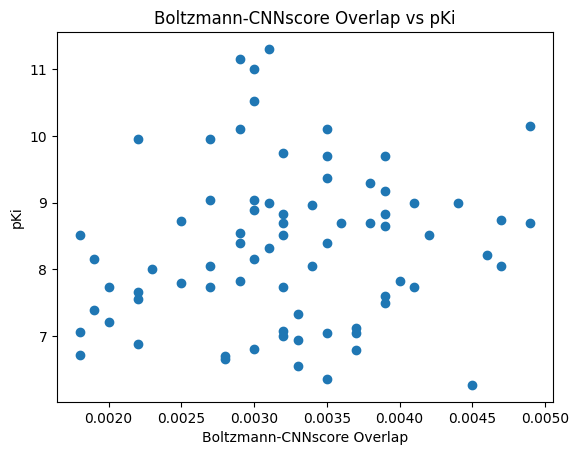

In [21]:
import matplotlib.pyplot as plt
plt.scatter(bol_cnnsc_df["RESP"], bol_cnnsc_df["pKi"])
plt.xlabel("Boltzmann-CNNscore Overlap")
plt.ylabel("pKi")
plt.title("Boltzmann-CNNscore Overlap vs pKi")